# Predicting Sales Prices

 ## Dataset Attributes

 The dataset contains information about houses in Ames, Iowa. The data was collected by the Ames City Assessor’s Office describing 2930 property sales which occurred in Ames, Iowa between 2006 and 2010. The dataset, containing 81 variables, was compiled and published by De Cock in 2011.

 Some of the variables contained in the original dataset have been removed from the the dataset provided to you.
 The dataset provided to you contains the following variables:
* **Year_Built:** year that the house was originally constructed
* **Year_Remod_Add:** year that the house was last remodelled
* **Total_Bsmt_SF:** total size of basement area in square feet
* **First_Flr_SF:** size of the first floor in square feet
* **Second_Flr_SF:** size of the second floor in square feet
* **Gr_Liv_Area:** size of above grade, ground living area in square feet
* **Full_Bath:** number of full above grade bathrooms in the house
* **Half_Bath:** number of half above grade bathrooms in the house
* **Bedroom_AbvGr:** number of above grade bedrooms (does not include basement bedrooms)
* **Kitchen_AbvGr:** number of above grade kitchens
* **TotRms_AbvGrd:** total number of above grade rooms (does not include bathrooms)
* **Fireplaces:** number of fireplaces in the house
* **Garage_Area:** size of garage in square feet
* **Sale_Price:** sale price of the house in dollars


*De Cock, D. (2011). "Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester
Regression Project," Journal of Statistics Education, Volume 19, Number 3.*

- https://ww2.amstat.org/publications/jse/v19n3/decock/DataDocumentation.txt
- http://ww2.amstat.org/publications/jse/v19n3/decock.pdf


 ## Objective

 The goal of this task is to analyse the relationship between these variables and build a multiple linear regression model to predict the sales prices based on the 'Gr_Liv_Area' and 'Garage_Area` variables.


In [1]:
# Import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics


In [2]:
# Read in the data set

df = pd.read_csv('ames.csv')
df.head()

,Year_Built,Year_Remod_Add,Total_Bsmt_SF,First_Flr_SF,Second_Flr_SF,Gr_Liv_Area,Full_Bath,Half_Bath,Bedroom_AbvGr,Kitchen_AbvGr,TotRms_AbvGrd,Fireplaces,Garage_Area,Sale_Price
0,1960,1960,1080,1656,0,1656,1,0,3,1,7,2,528,215000
1,1961,1961,882,896,0,896,1,0,2,1,5,0,730,105000
2,1958,1958,1329,1329,0,1329,1,1,3,1,6,0,312,172000
3,1968,1968,2110,2110,0,2110,2,1,3,1,8,2,522,244000
4,1997,1998,928,928,701,1629,2,1,3,1,6,1,482,189900


In [3]:
# Clean and pre-process the data if neccessary
# checking the amount of the missing data per column
missing_values_count = df.isnull().sum()

# Look at the number of missing values in all columns
print("Missing values per column:")
print(missing_values_count)
print(f"\nTotal missing values: {missing_values_count.sum()}")

Missing values per column:
Year_Built        0
Year_Remod_Add    0
Total_Bsmt_SF     0
First_Flr_SF      0
Second_Flr_SF     0
Gr_Liv_Area       0
Full_Bath         0
Half_Bath         0
Bedroom_AbvGr     0
Kitchen_AbvGr     0
TotRms_AbvGrd     0
Fireplaces        0
Garage_Area       0
Sale_Price        0
dtype: int64

Total missing values: 0


In [4]:
# Checking the data type of each column
print("Data types:")
print(df.dtypes)
print(f"\nDataset shape: {df.shape}")

Data types:
Year_Built        int64
Year_Remod_Add    int64
Total_Bsmt_SF     int64
First_Flr_SF      int64
Second_Flr_SF     int64
Gr_Liv_Area       int64
Full_Bath         int64
Half_Bath         int64
Bedroom_AbvGr     int64
Kitchen_AbvGr     int64
TotRms_AbvGrd     int64
Fireplaces        int64
Garage_Area       int64
Sale_Price        int64
dtype: object

Dataset shape: (2930, 14)


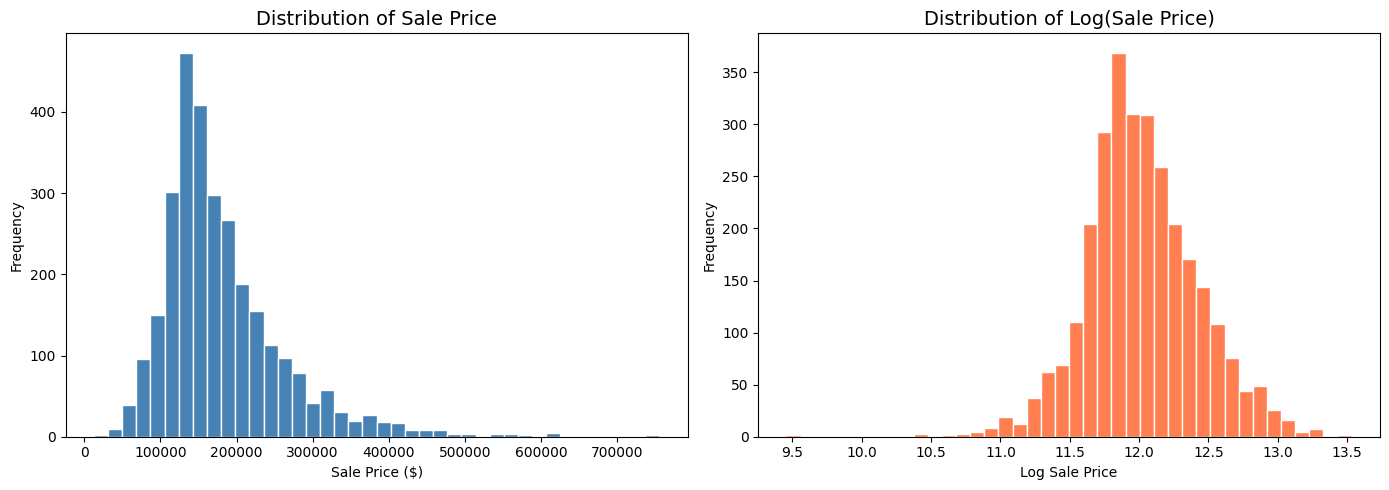

In [5]:
# Explore the data with visualisations such as histograms and correlation matrices
# Distribution of the dependent variable (Sale_Price)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['Sale_Price'], bins=40, color='steelblue', edgecolor='white')
axes[0].set_title('Distribution of Sale Price', fontsize=14)
axes[0].set_xlabel('Sale Price ($)')
axes[0].set_ylabel('Frequency')

axes[1].hist(np.log1p(df['Sale_Price']), bins=40, color='coral', edgecolor='white')
axes[1].set_title('Distribution of Log(Sale Price)', fontsize=14)
axes[1].set_xlabel('Log Sale Price')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

The distribution is right skewed, meaning the homes cluster in the lower price range. Price range varies from 12,789 dollars to 755,000 dollars.

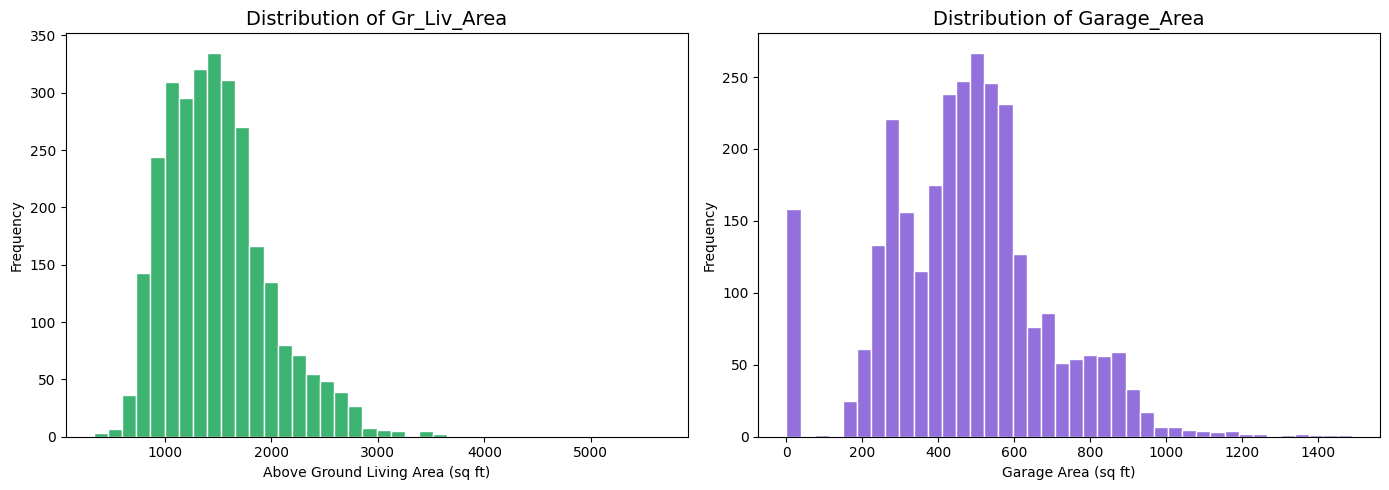

In [6]:
# Distribution of the independent variables
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['Gr_Liv_Area'], bins=40, color='mediumseagreen', edgecolor='white')
axes[0].set_title('Distribution of Gr_Liv_Area', fontsize=14)
axes[0].set_xlabel('Above Ground Living Area (sq ft)')
axes[0].set_ylabel('Frequency')

axes[1].hist(df['Garage_Area'], bins=40, color='mediumpurple', edgecolor='white')
axes[1].set_title('Distribution of Garage_Area', fontsize=14)
axes[1].set_xlabel('Garage Area (sq ft)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

Size above grade(Gr_Liv_Area) is also moderately right skewed, A few very large homes (up to 5,642 sq ft) represent outliers that can throw out the regression line out of proportion

Garage area is mostly normal distributed. It is noted that about 158 homes have zero garage area, indicating properties with no agarages.

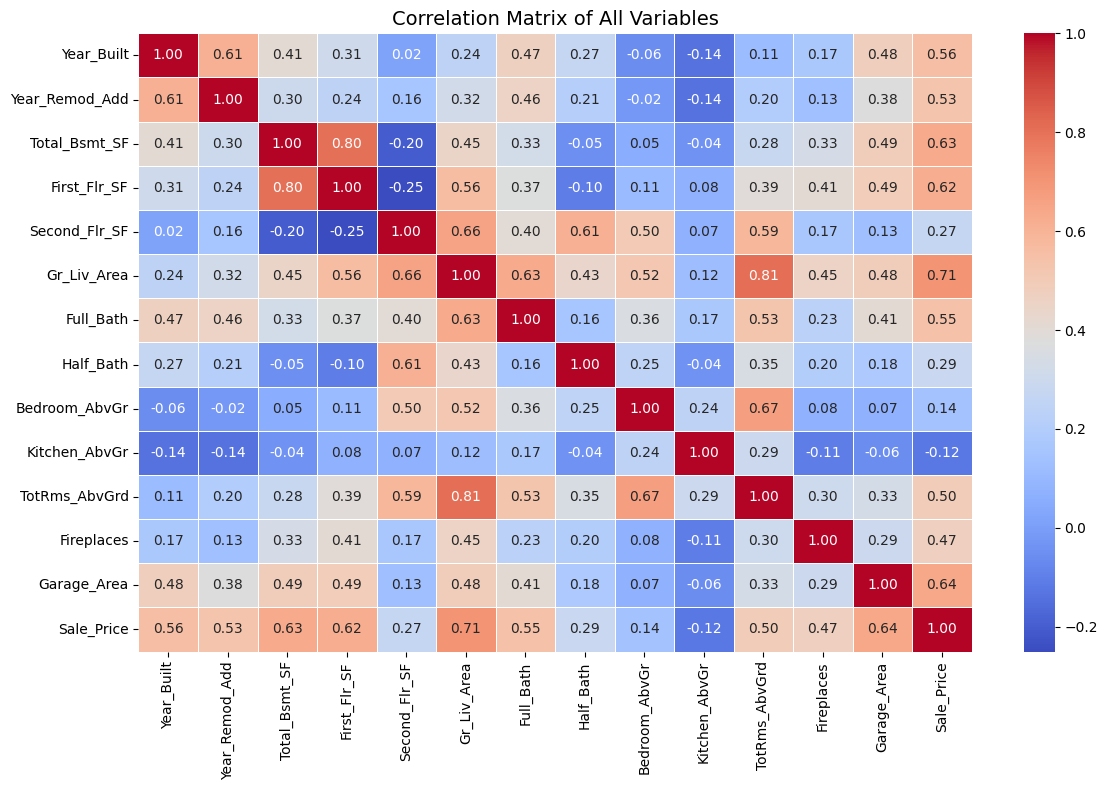

In [7]:
# Correlation matrix for all variables
plt.figure(figsize=(12, 8))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of All Variables', fontsize=14)
plt.tight_layout()
plt.show()

- Size above grade (Gr_Liv_Area) has the strongest correlation with Sale_Price (r = 0.71), making it the most informative predictor in the dataset
- Garage_Area is the strongest individual predictor (r =0.64), followed by the Total_Bsmt_SF which is the total size of the basement (r= 0.63) and First_Flr_SF which is the size of the first floor (r =0.62)
- Bedroom_AbvGr (r=0.14) and Kitchen_AbvGr(r=-0.12) have weak relationships with price

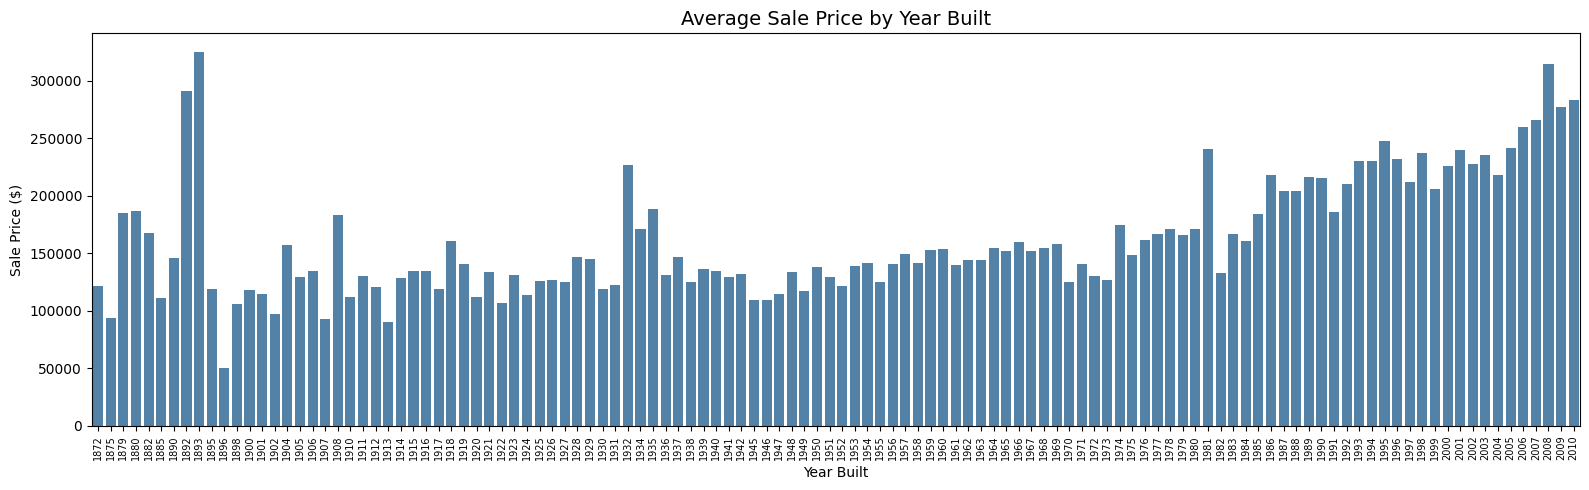

In [8]:
# Bar plot: Average Sale Price by Year Built
plt.figure(figsize=(16, 5))
sns.barplot(data=df, x='Year_Built', y='Sale_Price', color='steelblue', errorbar=None)
plt.title('Average Sale Price by Year Built', fontsize=14)
plt.xlabel('Year Built')
plt.ylabel('Sale Price ($)')
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

Recently bult houses have a higher sale price, although there are still houses built in 1892 and 1893 which have higher sales price but for most of them, are having lower sale price compared to the recently built houses.

In [9]:
# Split the independent variables from the dependent variable
X = df[['Gr_Liv_Area', 'Garage_Area']]
y = df['Sale_Price']

print("Independent variables (X) shape:", X.shape)
print("Dependent variable (y) shape:", y.shape)
print("\nFirst 5 rows of X:")
print(X.head())

Independent variables (X) shape: (2930, 2)
Dependent variable (y) shape: (2930,)

First 5 rows of X:
   Gr_Liv_Area  Garage_Area
0         1656          528
1          896          730
2         1329          312
3         2110          522
4         1629          482


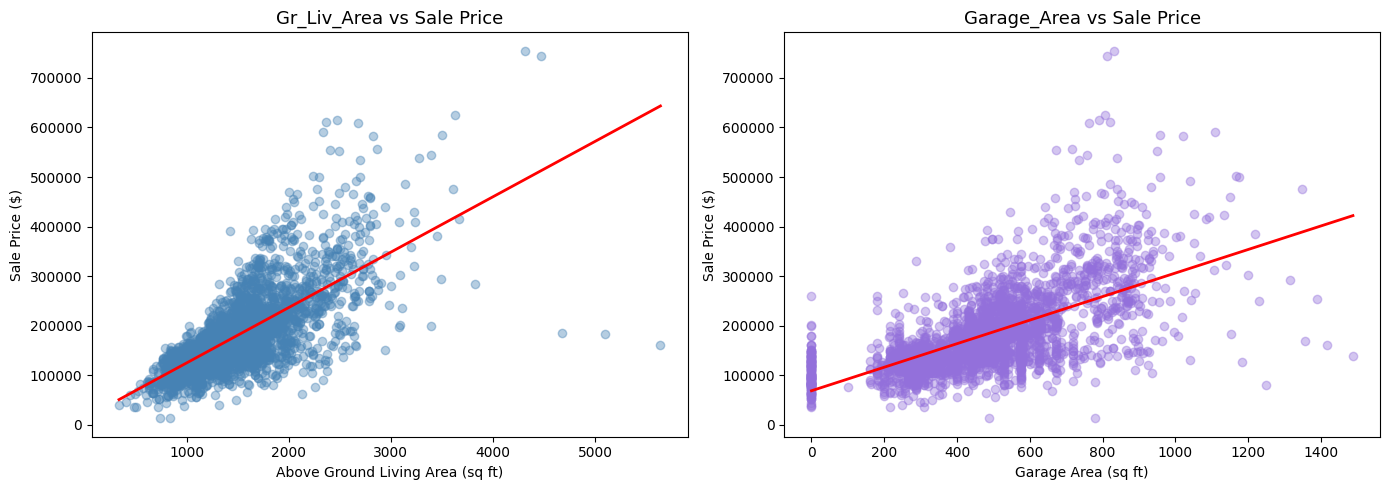

In [10]:
# Generate plots to explore the relationships between the independent and dependent variables
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df['Gr_Liv_Area'], df['Sale_Price'], alpha=0.4, color='steelblue')
m1, b1 = np.polyfit(df['Gr_Liv_Area'], df['Sale_Price'], 1)
x_line = np.linspace(df['Gr_Liv_Area'].min(), df['Gr_Liv_Area'].max(), 100)
axes[0].plot(x_line, m1 * x_line + b1, color='red', linewidth=2)
axes[0].set_title('Gr_Liv_Area vs Sale Price', fontsize=13)
axes[0].set_xlabel('Above Ground Living Area (sq ft)')
axes[0].set_ylabel('Sale Price ($)')

axes[1].scatter(df['Garage_Area'], df['Sale_Price'], alpha=0.4, color='mediumpurple')
m2, b2 = np.polyfit(df['Garage_Area'], df['Sale_Price'], 1)
x_line2 = np.linspace(df['Garage_Area'].min(), df['Garage_Area'].max(), 100)
axes[1].plot(x_line2, m2 * x_line2 + b2, color='red', linewidth=2)
axes[1].set_title('Garage_Area vs Sale Price', fontsize=13)
axes[1].set_xlabel('Garage Area (sq ft)')
axes[1].set_ylabel('Sale Price ($)')

plt.tight_layout()
plt.show()

In [11]:
# Create a training and test set with a 75:25 split ratio
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size:     {X_test.shape[0]} samples")

Training set size: 2197 samples
Test set size:     733 samples


In [12]:
# Build a multiple linear regression model using 'Gr_Liv_Area' and 'Garage_Area'
model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


In [13]:
# Print the trained model's intercept and coefficients
print(f"Intercept:  {model.intercept_:.4f}")
print(f"Coefficient for Gr_Liv_Area:  {model.coef_[0]:.4f}")
print(f"Coefficient for Garage_Area:  {model.coef_[1]:.4f}")

Intercept:  -5059.4482
Coefficient for Gr_Liv_Area:  78.6929
Coefficient for Garage_Area:  141.1457


In [14]:
# Generate predictions for the test set
y_pred = model.predict(X_test)

# Preview actual vs predicted
results = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred.round(2)})
print(results.head(10))

   Actual  Predicted
0  161000  158224.09
1  116000  113256.68
2  196500  217552.82
3  123600   72846.49
4  126000   94782.71
5  174190  159556.52
6  200000  147050.45
7  148500  171621.48
8   88750   81392.39
9  409900  283579.84


In [15]:
# Evaluate the model's performance by computing the mean squared error (MSE) or root mean squared error (RMSE) on the test set using sklearn.metrics.
mse  = metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = metrics.r2_score(y_test, y_pred)

print(f"Mean Squared Error  (MSE):  {mse:,.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

Mean Squared Error  (MSE):  2,634,371,879.69
Root Mean Squared Error (RMSE): 51,326.13
R² Score: 0.6386


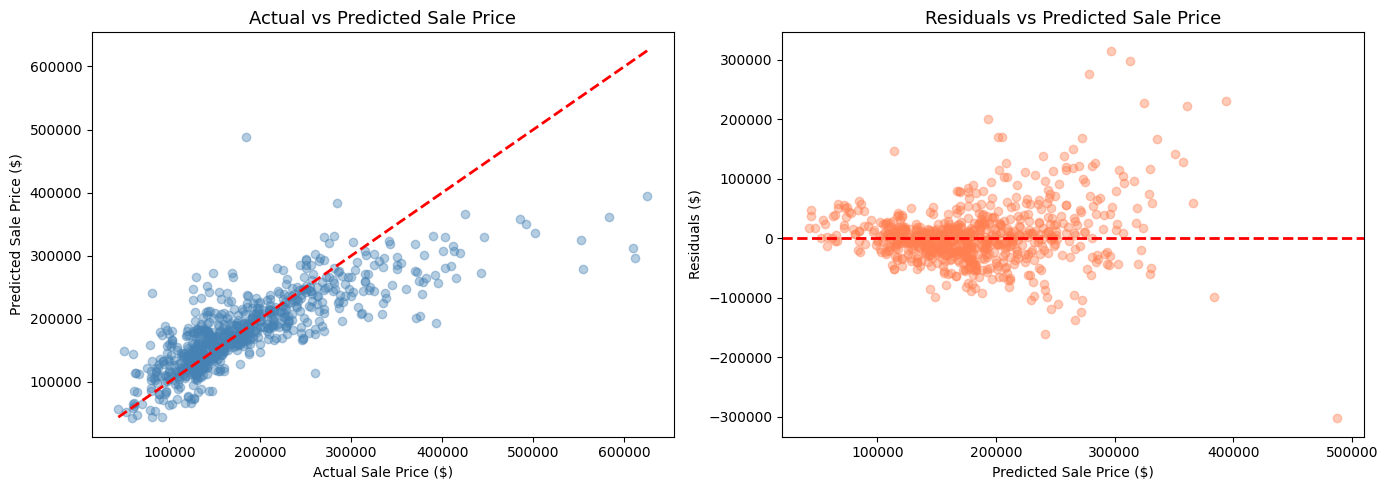

In [16]:
# Generate an error plot to visualise the differences between the predicted and actual values in the test set.
residuals = y_test.values - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter: Actual vs Predicted
axes[0].scatter(y_test, y_pred, alpha=0.4, color='steelblue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
axes[0].set_title('Actual vs Predicted Sale Price', fontsize=13)
axes[0].set_xlabel('Actual Sale Price ($)')
axes[0].set_ylabel('Predicted Sale Price ($)')

# Residual plot
axes[1].scatter(y_pred, residuals, alpha=0.4, color='coral')
axes[1].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[1].set_title('Residuals vs Predicted Sale Price', fontsize=13)
axes[1].set_xlabel('Predicted Sale Price ($)')
axes[1].set_ylabel('Residuals ($)')

plt.tight_layout()
plt.show()

In [17]:
# Print the coefficients and interpret them within the context of the median value prediction.
print("=== Model Equation ===")
print(f"Sale_Price = {model.intercept_:.2f} + {model.coef_[0]:.2f} * Gr_Liv_Area + {model.coef_[1]:.2f} * Garage_Area")
print()
print("=== Coefficients ===")
print(f"• Intercept ({model.intercept_:.2f})")
print(f"• Gr_Liv_Area ({model.coef_[0]:.2f})")
print(f"• Garage_Area ({model.coef_[1]:.2f})")

=== Model Equation ===
Sale_Price = -5059.45 + 78.69 * Gr_Liv_Area + 141.15 * Garage_Area

=== Coefficients ===
• Intercept (-5059.45)
• Gr_Liv_Area (78.69)
• Garage_Area (141.15)


**Interpret coefficients in the context of the prediction:**
- The baseline predicted sale price when both Gr_Liv_Area and Garage_Area are 0.
- For each additional square foot of above-grade living area.
- The sale price increases by approximately 78.69 dollars, holding Garage_Area constant.
- For each additional square foot of garage area, the sale price increases by approximately $141.15, holding Gr_Liv_Area constant.

**Summarise findings**
- Most homes cluster in the lower price range.
- About 158 homes have no garage.
- Size above grade, garage area and total basement area have the strong correlation to the price, with size above grade having the strongest.
- The model explains ~64% variance according to R squared score.
- RMSE is 51,326 dollars which means predictions are off by over 51,000 dollars on average.
- Expanding the feature set, addressing the skewness and handling outliers would improve the prediction accuracy.